# End to end: 1-D dam break

Goal: run a 1-D dam break from the model to a plot on the NumPy backend.

Prerequisites: [Model and SystemModel](model_system_model.ipynb), [NumericalSystemModel](numerical_system_model.ipynb).

In [1]:
import numpy as np

import zoomy_core.model.boundary_conditions as BC
import zoomy_core.model.initial_conditions as IC
from zoomy_core.model.models import SME, Newtonian, NavierSlip, StressFree

model = SME(
    level=0,
    closures=[Newtonian(), NavierSlip(), StressFree()],
    boundary_conditions=BC.BoundaryConditions([BC.Wall(tag="left"), BC.Wall(tag="right")]),
    initial_conditions=IC.RP(
        high=lambda n: np.array([0.0, 2.0, 0.0]),
        low=lambda n: np.array([0.0, 1.0, 0.0]),
        jump_position_x=5.0),
)

In [2]:
from zoomy_core.numerics import NumericalSystemModel, ReconstructionSpec
from zoomy_core.systemmodel import SystemModel

sm = SystemModel.from_model(model)
nsm = NumericalSystemModel.from_system_model(sm, reconstruction=ReconstructionSpec(order=1))
nsm.describe()

**SystemModel** — 3 equations, 1 spatial dimension

**Parameters:** $g = 9.81$, $\rho = 1.0$, $\nu = 0.0$, $\lambda_{s} = 0.0$, $e_{x} = 0.0$

**System form:**

$$M(Q)\,\partial_t Q + \nabla\cdot\!\big(F(Q) + P(Q)\big) + \sum_{d} B_{d}(Q)\,\partial_{d} Q - \nabla\cdot\!\big(A(Q)\,\nabla Q\big) - S(Q) = 0$$

**State $Q$:**

$$
\left[\begin{matrix}b\\h\\q_{0}\end{matrix}\right]
$$

**Auxiliary $Q_{aux}$:**

$$
\left[\begin{matrix}dq0dx\\dhdx\\dbdx\\hinv\end{matrix}\right]
$$

**Mass matrix $M$:**

$$
\left[\begin{matrix}1 & 0 & 0\\0 & 1 & 0\\0 & 0 & 1\end{matrix}\right]
$$

**Flux $F$:**

$$
\left[\begin{matrix}0\\q_{0}\\hinv q_{0}^{2}\end{matrix}\right]
$$

**Hydrostatic pressure $P$:**

$$
\left[\begin{matrix}0\\0\\\frac{g h^{2}}{2}\end{matrix}\right]
$$

**Diffusive flux $A$ $= 0$**

**NCP $B$:**

$$
\left[\begin{matrix}0 & 0 & 0\\0 & 0 & 0\\g h & 0 & 0\end{matrix}\right]
$$

**Source $S$ (implicit):**

$$
\left[\begin{matrix}0\\0\\e_{x} g h - \frac{hinv \lambda_{s} q_{0}}{\rho}\end{matrix}\right]
$$

**Operations:** from_model, declare_roles, declare_tags, declare_roles, declare_tags, normalize_face_normal, register_aux, regularize_pow, desingularize_hinv, gate_eigenvalues_dry

In [3]:
from zoomy_core.mesh import LSQMesh
from zoomy_core.symsolver.numpy_backend import SymbolicHyperbolicSolverNumpy

mesh = LSQMesh.create_1d(domain=(0.0, 10.0), n_inner_cells=200)
solver = SymbolicHyperbolicSolverNumpy(time_end=1.0, cfl=0.9)
Q0, Qaux = solver.setup(mesh, nsm)
time, Q, Qaux = solver.run(Q0.copy(), Qaux)
print(f"t = {time}")

t = 1.0


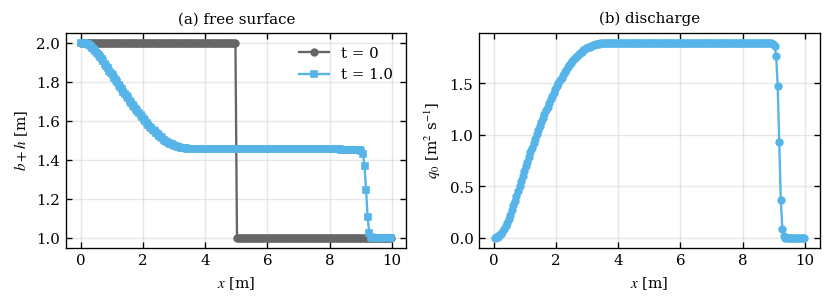

In [4]:
import matplotlib.pyplot as plt
import zoomy_plotting as zp

x = mesh.cell_centers[0, :mesh.n_inner_cells]
with zp.apply_style():
    fig, (ax_h, ax_q) = plt.subplots(1, 2, figsize=(7.0, 2.6))
    zp.line_plot(ax_h, [
        {"x": x, "y": Q0[0] + Q0[1], "label": "t = 0", "role": "reference"},
        {"x": x, "y": Q[0] + Q[1], "label": f"t = {time}", "role": "water"},
    ], xlabel="$x$ [m]", ylabel="$b + h$ [m]", title="(a) free surface")
    zp.line_plot(ax_q, [
        {"x": x, "y": Q[2], "label": f"t = {time}", "role": "water"},
    ], xlabel="$x$ [m]", ylabel="$q_0$ [m$^2$ s$^{-1}$]", title="(b) discharge")
    ax_h.legend()
    fig.tight_layout()

In [5]:
assert abs(Q[1].sum() - 300.0) < 1e-9
assert Q[1].min() >= 1.0 - 1e-6 and Q[1].max() <= 2.0 + 1e-6
assert np.abs(Q[2]).max() > 0.1